# Cross-Sectional Feature Engineering & Scaling Pipeline


1. Construct a causally-correct target variable: **1-day forward market-relative log return** ($y_{i,t} = r_{i, t \to t+1} - \bar{r}_t$).
2. Engineer **25+ indicators** across single-stock OHLCV, macro/market sentiment, and options/short interest.
3. Implement a **Two-Stage Causal Scaling Pipeline** (Cross-Sectional Z-Score for single stock; Rolling Time-Series Z-Score for macro).
4. Perform **Two-Tier Feature Selection** (Univariate Profit Factor filter & Mutual Information screening).

In [13]:
import numpy as np
import pandas as pd
import talib as ta
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import norm
import warnings
warnings.filterwarnings("ignore")

# PACF analysis (proposal: "PACF informs the choice of autoregressive return lags").
# Optional dependency - guarded so the notebook still runs if statsmodels is absent.
try:
    from statsmodels.tsa.stattools import pacf
    HAS_PACF = True
except Exception:
    HAS_PACF = False

# Set visualization parameters
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
print("Environment initialized successfully.")

Environment initialized successfully.


## Data Loading & Causal Target Variable Construction
Construct the forward 1-day market-neutral log return:
$$r_{i, t \to t+1} = \ln\left(\frac{\text{AdjClose}_{i, t+1}}{\text{AdjClose}_{i, t}}\right)$$
$$y_{i,t} = r_{i, t \to t+1} - \frac{1}{N} \sum_{j=1}^{N} r_{j, t \to t+1}$$
*Note: This target is strictly cross-sectionally demeaned and strictly forward-shifted per ticker.*

In [14]:
# Load base equity dataset
df = pd.read_csv("final_portfolio_data.csv", parse_dates=["Date"])
df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)

# Compute 1-day forward log return per ticker
df["fwd_log_ret"] = df.groupby("Ticker")["Adj Close"].transform(
    lambda x: np.log(x.shift(-1) / x)
)

# Cross-sectional daily mean market return
df["cs_mean_ret"] = df.groupby("Date")["fwd_log_ret"].transform("mean")

# Market-neutral relative return target
df["target"] = df["fwd_log_ret"] - df["cs_mean_ret"]
df = df.drop(columns=["cs_mean_ret"])

print(f"Dataset Loaded: {df['Ticker'].nunique()} Tickers | Date Range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
print(f"Target Variable 'target' created with shape: {df.shape}")

Dataset Loaded: 20 Tickers | Date Range: 2021-07-26 to 2026-07-24
Target Variable 'target' created with shape: (25100, 10)


## Single-Stock Target-OHLCV Features
TA-Lib oscillators and Timothy Masters microstructure indicators, all derived from each stock's OHLCV bar.

| Group | Features |
|---|---|
| TA-Lib oscillators | RSI(14), MACD-hist, PPO, ROC(10), ADX(14) |
| Volatility / range | ATR/Close, Bollinger %B, realized-vol(20d), intraday range |
| Volume flow | relative volume, CMMA(10), CMF(20) |
| Momentum | mom_5 (weekly), mom_21 (monthly) |

In [15]:
def compute_stock_features(group):
    c, h, l, v = group["Adj Close"], group["High"], group["Low"], group["Volume"]

    # TA-Lib Oscillators
    group["rsi_14"] = (ta.RSI(c, timeperiod=14) - 50.0) / 50.0
    group["macd_hist"] = np.arcsinh(ta.MACD(c)[2] / (c + 1e-8))
    group["ppo"] = ta.PPO(c) / 100.0
    group["roc_10"] = ta.ROC(c, timeperiod=10) / 100.0
    group["atr_norm"] = np.log1p(ta.ATR(h, l, c, timeperiod=14) / (c + 1e-8))
    group["adx_14"] = ta.ADX(h, l, c, timeperiod=14) / 100.0

    upper, middle, lower = ta.BBANDS(c, timeperiod=20)
    group["bollinger_pct_b"] = (c - lower) / (upper - lower + 1e-8)
    group["rel_volume"] = np.log1p(v / (v.rolling(20).mean() + 1e-8))
    # High-low intraday RANGE (volatility/microstructure proxy) - NOT a bid-ask spread.
    group["intraday_range_pct"] = (h - l) / (c + 1e-8)

    # Timothy Masters: CMMA(10) and Chaikin Money Flow(20)
    group["cmma_10"] = (c - ta.SMA(c, timeperiod=10)) / (c + 1e-8)
    group['cmma_5'] = (c - ta.SMA(c, timeperiod=5)) / (c + 1e-8)
    ii = (2 * c - h - l) / (h - l + 1e-8) * v
    group["cmf_20"] = ii.rolling(20).sum() / (v.rolling(20).sum() + 1e-8)

    # Realized Volatility (20d, annualized)
    log_ret = np.log(c / (c.shift(1) + 1e-8))
    group["realized_vol_20"] = log_ret.rolling(20).std() * np.sqrt(252)

    # PACF-informed autoregressive return lags: 5d (weekly) and 21d (monthly)
    group["mom_5"] = np.log(c / (c.shift(5) + 1e-8))
    group["mom_21"] = np.log(c / (c.shift(21) + 1e-8))
    return group

ticker_dfs = []
for ticker, grp in df.groupby("Ticker"):
    ticker_dfs.append(compute_stock_features(grp.copy()))
df = pd.concat(ticker_dfs, ignore_index=True).sort_values(["Date", "Ticker"]).reset_index(drop=True)

## Macro & Market-Level Feature

In [16]:
start_date = df["Date"].min().strftime("%Y-%m-%d")
# yfinance's `end` is EXCLUSIVE, so without the +1 day the panel's last
# trading day would silently be dropped from the macro pull (and only
# papered over by the ffill below). Push it out by a day to include it.
end_date = (df["Date"].max() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

# ^GSPC is fetched to build stock-specific risk features (beta, idio-vol) next.
macro_map = {"^VIX": "vix_level", "^GSPC": "sp500_close"}

m_raw = yf.download(list(macro_map.keys()), start=start_date, end=end_date, progress=False)
if isinstance(m_raw.columns, pd.MultiIndex):
    m_raw = m_raw["Close"] if "Close" in m_raw.columns.levels[0] else m_raw["Adj Close"]
m_raw = m_raw.rename(columns=macro_map).reset_index()

# Market-wide feature retained per proposal
m_raw["vix_5d_change"] = m_raw["vix_level"] - m_raw["vix_level"].shift(5)
# Market daily log return (intermediate -> feeds beta / idio-vol; NOT a panel feature)
m_raw["mkt_ret"] = np.log(m_raw["sp500_close"] / (m_raw["sp500_close"].shift(1) + 1e-8))

macro_cols = ["vix_5d_change"]  # only market-wide feature retained
df = pd.merge(df, m_raw[["Date"] + macro_cols + ["mkt_ret"]], on="Date", how="left")
# Causal fill ONLY (no bfill -> no look-ahead)
df[macro_cols + ["mkt_ret"]] = df[macro_cols + ["mkt_ret"]].ffill()

In [17]:
# ------------------------------------------------------------------
# Exogenous risk-model & sector features.
# These VARY across tickers, so (unlike market-wide macro) they carry
# standalone cross-sectional signal for the demeaned long-short target.
#   * 60d market beta        beta_i,t = Cov(r_i, r_m) / Var(r_m)  [rolling 60d]
#   * 60d idiosyncratic vol  sd(r_i - beta*r_m) over 60d, annualized
#   * sector-relative 21d return  r_i,21d - mean(r_j,21d in same GICS sector)
# ------------------------------------------------------------------
df["log_ret"] = df.groupby("Ticker")["Adj Close"].transform(
    lambda x: np.log(x / (x.shift(1) + 1e-8))
)

def add_risk_features(g):
    cov = g["log_ret"].rolling(60).cov(g["mkt_ret"])
    var = g["mkt_ret"].rolling(60).var()
    g["beta_60"] = cov / (var + 1e-8)
    resid = g["log_ret"] - g["beta_60"] * g["mkt_ret"]
    g["idio_vol_60"] = resid.rolling(60).std() * np.sqrt(252)
    g["ret_21d"] = np.log(g["Adj Close"] / (g["Adj Close"].shift(21) + 1e-8))
    return g

df = df.groupby("Ticker", group_keys=False).apply(add_risk_features)

# --- Sector membership: try yfinance, fall back to a hardcoded GICS map ---
# yfinance's `.info["sector"]` uses GICS-style labels that differ slightly from
# the fallback map below (e.g. "Financial Services" vs "Financials",
# "Consumer Cyclical" vs "Consumer Discretionary", "Consumer Defensive" vs
# "Consumer Staples"). Left unreconciled, a ticker could land in a different
# sector bucket depending on whether the live pull or the fallback fired,
# which would silently corrupt the sector-relative-return grouping below.
SECTOR_ALIASES = {
    "Financial Services": "Financials",
    "Consumer Cyclical": "Consumer Discretionary",
    "Consumer Defensive": "Consumer Staples",
}

SECTOR_FALLBACK = {
    "BLKB": "Technology", "BOOT": "Consumer Discretionary", "CACC": "Financials",
    "CALM": "Consumer Staples", "CNXC": "Technology", "EWBC": "Financials",
    "EXP": "Materials", "FTI": "Energy", "HNI": "Industrials", "LQDA": "Healthcare",
    "MDU": "Utilities", "NGS": "Energy", "RGA": "Financials", "RSI": "Consumer Discretionary",
    "SAIA": "Industrials", "STRL": "Industrials", "TWLO": "Technology",
    "USLM": "Materials", "WSBC": "Financials", "XPO": "Industrials",
}

def fetch_sector(tkr):
    try:
        s = yf.Ticker(tkr).info.get("sector")
        s = SECTOR_ALIASES.get(s, s)
        return s if s else SECTOR_FALLBACK.get(tkr, "Unknown")
    except Exception:
        return SECTOR_FALLBACK.get(tkr, "Unknown")

sectors = {t: fetch_sector(t) for t in df["Ticker"].unique()}
df["Sector"] = df["Ticker"].map(sectors)
print("Sector assignment:", sectors)

# Sector-relative 21d return (equal-weight sector basket within the 20-stock universe).
# Single-member sectors (e.g. CALM, LQDA, MDU here) have no peers to compare
# against, so "sector-relative" is undefined for them -> NaN (handled by the
# pipeline imputer / feature-selection dropna), rather than silently
# defaulting to ~0, which would otherwise masquerade as a real "in line with
# sector" signal instead of "no sector to compare to".
sector_group_size = df.groupby(["Date", "Sector"])["ret_21d"].transform("size")
sector_mean_21d = df.groupby(["Date", "Sector"])["ret_21d"].transform("mean")
df["sector_rel_21"] = np.where(sector_group_size > 1, df["ret_21d"] - sector_mean_21d, np.nan)

# Drop intermediates
df = df.drop(columns=["log_ret", "ret_21d", "mkt_ret"])

exog_risk_cols = ["beta_60", "idio_vol_60", "sector_rel_21"]
print(f"Exogenous risk features computed: {exog_risk_cols}")

Sector assignment: {'BLKB': 'Technology', 'BOOT': 'Consumer Discretionary', 'CACC': 'Financials', 'CALM': 'Consumer Staples', 'CNXC': 'Technology', 'EWBC': 'Financials', 'EXP': 'Basic Materials', 'FTI': 'Energy', 'HNI': 'Consumer Discretionary', 'LQDA': 'Healthcare', 'MDU': 'Utilities', 'NGS': 'Energy', 'RGA': 'Financials', 'RSI': 'Consumer Discretionary', 'SAIA': 'Industrials', 'STRL': 'Industrials', 'TWLO': 'Technology', 'USLM': 'Basic Materials', 'WSBC': 'Financials', 'XPO': 'Industrials'}
Exogenous risk features computed: ['beta_60', 'idio_vol_60', 'sector_rel_21']


## WRDS OptionMetrics Features (exogenous, stock-specific)
Firm-specific option-market signals. These **vary across tickers**, so (unlike market-wide macro) they carry standalone cross-sectional signal:

1. `stock_pcr` — put/call volume ratio (3-day median, clipped to `[0, 5]` to kill near-zero-denominator blow-ups)
2. `iv_30d` — 30-day ATM implied volatility
3. `iv_skew` — 25-delta IV skew (put IV − call IV)
4. `gex` — net gamma exposure (market-maker hedging pressure)
5. `bid_ask_spread` — ATM option quoted spread `(ask − bid) / mid`, an exogenous liquidity proxy for the underlying

Notes:
- `optionm.opprcd2026` does not yet exist on WRDS, so option features for Jan–Jul 2026 are left as **NaN** (not fabricated) and surfaced to the pipeline imputer.

In [18]:
# ==========================================================
# WRDS Connection (OptionMetrics only; short-interest intentionally omitted)
# Mapping path: ticker --crsp.msenames--> permno --opcrsphist--> secid
# then year-partitioned option chains optionm.opprcdYYYY
# ==========================================================
import wrds
import numpy as np
import pandas as pd

def to_sql_tuple(iterable):
    """Formats Python iterables into safe SQL IN clauses, preventing 1-element tuple syntax errors."""
    items = list(iterable)
    if not items:
        return "('')"
    if len(items) == 1:
        item = items[0]
        return f"('{item}')" if isinstance(item, str) else f"({item})"
    return str(tuple(items))

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)

# WRDS username: read from the WRDS_USERNAME environment variable first
# (e.g. `export WRDS_USERNAME=yourid` before launching Jupyter), and only
# prompt interactively as a fallback. Never hardcode/commit a real username
# in a shared notebook.
import os
import getpass

WRDS_USERNAME = os.environ.get("WRDS_USERNAME") or getpass.getpass("WRDS username: ")
if not WRDS_USERNAME:
    raise ValueError(
        "WRDS_USERNAME is blank -> db=None -> NO WRDS data will be pulled.\n"
        "Set the WRDS_USERNAME environment variable (or enter it at the prompt) and re-run."
    )

db = wrds.Connection(wrds_username=WRDS_USERNAME)

tickers   = tuple(df["Ticker"].unique().tolist())
start_str = df["Date"].min().strftime("%Y-%m-%d")
end_str   = df["Date"].max().strftime("%Y-%m-%d")
yr_lo, yr_hi = df["Date"].min().year, df["Date"].max().year
print(f"Querying WRDS for {len(tickers)} tickers | {start_str} -> {end_str}")

Loading library list...
Done
Querying WRDS for 20 tickers | 2021-07-26 -> 2026-07-24


In [19]:
# 0) ticker -> permno (CRSP msenames, active during window)
permno_df = pd.DataFrame()
try:
    permno_df = db.raw_sql(f"""
        SELECT permno, ticker FROM crsp.msenames
        WHERE ticker IN {to_sql_tuple(tickers)}
          AND namedt <= '{end_str}' AND nameendt >= '{start_str}'
    """)
    print(f"[1] permno resolved: {permno_df['ticker'].nunique()}/{len(tickers)} tickers")
except Exception as e:
    print(f"[1] crsp.msenames lookup failed: {e}")

# 1) permno -> secid (WRDS CRSP-OptionMetrics link: opcrsphist)
secid_map = pd.DataFrame()
if not permno_df.empty:
    permnos = permno_df["permno"].dropna().astype(int).unique().tolist()
    try:
        link_df = db.raw_sql(f"""
            SELECT secid, permno, sdate, edate
            FROM wrdsapps_link_crsp_optionm.opcrsphist
            WHERE permno IN {to_sql_tuple(permnos)}
              AND sdate <= '{end_str}' AND edate >= '{start_str}'
        """)
        secid_map = permno_df.merge(link_df, on="permno")
        print(f"[2] secid links: {len(secid_map)} rows | tickers: {secid_map['ticker'].nunique()}")

        if not secid_map.empty:
            # A ticker can map to >1 secid if CRSP has multiple overlapping
            # permno/secid link rows in this window (e.g. a ticker symbol
            # reused by a different company). Left undeduplicated, the later
            # groupby(["ticker", "date"]) aggregations would silently sum
            # volume/gamma across unrelated instruments. Keep only the link
            # whose [sdate, edate] window overlaps our analysis window most.
            win_start, win_end = pd.Timestamp(start_str), pd.Timestamp(end_str)
            secid_map["sdate"] = pd.to_datetime(secid_map["sdate"])
            secid_map["edate"] = pd.to_datetime(secid_map["edate"])
            overlap_start = secid_map["sdate"].clip(lower=win_start)
            overlap_end = secid_map["edate"].clip(upper=win_end)
            secid_map["overlap_days"] = (overlap_end - overlap_start).dt.days.clip(lower=0)

            dupe_counts = secid_map.groupby("ticker")["secid"].nunique()
            ambiguous = dupe_counts[dupe_counts > 1].index.tolist()
            if ambiguous:
                print(f"[2] WARNING: multiple secid candidates for {ambiguous} "
                      f"-> keeping the link with the largest date overlap for each.")

            secid_map = (secid_map.sort_values("overlap_days", ascending=False)
                         .drop_duplicates(subset="ticker", keep="first")
                         .drop(columns=["overlap_days"]))
            print(f"[2] secid links after dedup: {len(secid_map)} rows | tickers: {secid_map['ticker'].nunique()}")
    except Exception as e:
        print(f"[2] opcrsphist link failed: {e}")

secids = secid_map["secid"].dropna().astype(int).unique().tolist() if not secid_map.empty else []
print(f"[2] unique secids to query: {len(secids)}")

# Probe for a QUOTED-SPREAD column PAIR: need BOTH best_bid and an ask-side column.
# Only feeds bid_ask_spread. If the pair is absent, that ONE feature stays NaN and the
# core option pull below is completely unaffected.
ask_col = None
try:
    probe = db.raw_sql(
        "SELECT column_name FROM information_schema.columns "
        "WHERE table_schema='optionm' AND table_name='opprcd2024'"
    )
    avail = set(probe["column_name"])
    if "best_bid" in avail:
        for cand in ["best_offer", "best_ask"]:
            if cand in avail:
                ask_col = cand
                break
    print(f"[2] option quote pair: best_bid + {ask_col}")
except Exception as e:
    print(f"[2] quote-column probe skipped: {e}")

# 2) Pull option chains per year. Try WITH quote columns first; on ANY error fall back
#    to the plain (proven) SELECT so the four core features are NEVER lost.
extra_select = f", best_bid, {ask_col} AS ask" if ask_col else ""

def _pull_year(y, with_quotes):
    sel = extra_select if with_quotes else ""
    return db.raw_sql(f"""
        SELECT secid, date, cp_flag, volume, open_interest,
               impl_volatility AS iv, delta, gamma{sel}
        FROM optionm.opprcd{y}
        WHERE secid IN {to_sql_tuple(secids)}
          AND date BETWEEN '{start_str}' AND '{end_str}'
          AND volume > 0
    """, date_cols=["date"])

opt_parts = []
if secids:
    for y in range(yr_lo, yr_hi + 1):
        try:
            part = _pull_year(y, with_quotes=bool(extra_select))
            tag = " (+quotes)" if extra_select else ""
            print(f"[3]   optionm.opprcd{y}: {len(part):,} rows{tag}")
            opt_parts.append(part)
        except Exception as e:
            if extra_select:
                # Quote-enriched query failed (e.g. best_bid not a column in this vintage).
                # Retry the proven plain select so core features survive.
                try:
                    part = _pull_year(y, with_quotes=False)
                    print(f"[3]   optionm.opprcd{y}: {len(part):,} rows (quotes dropped: {e})")
                    opt_parts.append(part)
                except Exception as e2:
                    print(f"[3]   optionm.opprcd{y} skipped: {e2}")
            else:
                print(f"[3]   optionm.opprcd{y} skipped: {e}")

if opt_parts:
    opt = pd.concat(opt_parts, ignore_index=True)
    opt["date"] = pd.to_datetime(opt["date"])
    opt = opt.merge(secid_map[["secid", "ticker"]].drop_duplicates(), on="secid")
    spot = df[["Ticker", "Date", "Adj Close"]].rename(
        columns={"Ticker": "ticker", "Date": "date", "Adj Close": "spot"}
    )
    opt = opt.merge(spot, on=["ticker", "date"], how="left")
else:
    opt = pd.DataFrame()
print(f"[3] Option chain rows assembled: {len(opt):,}")

# 3) Put/Call Volume Ratio (stock_pcr) with outlier clipping
if not opt.empty:
    pcr = opt.groupby(["ticker", "date", "cp_flag"])["volume"].sum().unstack("cp_flag", fill_value=0)
    pcr.columns = [str(c).upper() for c in pcr.columns]
    calls = pcr["C"] if "C" in pcr.columns else 0
    puts  = pcr["P"] if "P" in pcr.columns else 0
    pcr["stock_pcr"] = puts / (calls + 1e-8)
    pcr = pcr.reset_index().rename(columns={"ticker": "Ticker", "date": "Date"})
    # 3-day median de-noise, then clip pathological blow-ups from near-zero call volume
    pcr["stock_pcr"] = pcr.groupby("Ticker")["stock_pcr"].transform(
        lambda x: x.rolling(3, min_periods=1).median()
    )
    pcr["stock_pcr"] = pcr["stock_pcr"].clip(lower=0.0, upper=5.0)
else:
    pcr = pd.DataFrame(columns=["Ticker", "Date", "stock_pcr"])

# 4) 30-day ATM IV (iv_30d) + 25-delta IV Skew (iv_skew)
if not opt.empty:
    opt["abs_delta"] = opt["delta"].abs()
    atm = (opt[(opt["abs_delta"] >= 0.45) & (opt["abs_delta"] <= 0.55)]
           .groupby(["ticker", "date"])["iv"].mean()
           .reset_index().rename(columns={"iv": "iv_30d", "ticker": "Ticker", "date": "Date"}))
    w25 = opt[(opt["abs_delta"] >= 0.20) & (opt["abs_delta"] <= 0.30)]
    put25  = w25[w25["cp_flag"] == "P"].groupby(["ticker", "date"])["iv"].mean()
    call25 = w25[w25["cp_flag"] == "C"].groupby(["ticker", "date"])["iv"].mean()
    skew = (put25 - call25).reset_index().rename(columns={"iv": "iv_skew", "ticker": "Ticker", "date": "Date"})
    iv_feat = atm.merge(skew, on=["Ticker", "Date"], how="outer")
else:
    iv_feat = pd.DataFrame(columns=["Ticker", "Date", "iv_30d", "iv_skew"])

# 5) Net Gamma Exposure (gex)
if not opt.empty:
    opt["gex_signed"] = (opt["gamma"] * opt["open_interest"] * (opt["spot"] ** 2) * 0.01) * np.where(opt["cp_flag"] == "C", 1, -1)
    gex = (opt.groupby(["ticker", "date"])["gex_signed"]
           .sum().reset_index()
           .rename(columns={"gex_signed": "gex", "ticker": "Ticker", "date": "Date"}))
else:
    gex = pd.DataFrame(columns=["Ticker", "Date", "gex"])

# 6) Bid-Ask Quoted Spread (ATM option quote -> exogenous liquidity proxy for the underlying)
if not opt.empty and ask_col and {"best_bid", "ask"}.issubset(opt.columns):
    qd = opt[(opt["abs_delta"] >= 0.45) & (opt["abs_delta"] <= 0.55) &
             (opt["best_bid"] > 0) & (opt["ask"] > 0)].copy()
    qd["mid"] = (qd["best_bid"] + qd["ask"]) / 2.0
    qd["spread"] = (qd["ask"] - qd["best_bid"]) / (qd["mid"] + 1e-8)
    ba = (qd.groupby(["ticker", "date"])["spread"].mean()
          .reset_index().rename(columns={"spread": "bid_ask_spread", "ticker": "Ticker", "date": "Date"}))
else:
    ba = pd.DataFrame(columns=["Ticker", "Date", "bid_ask_spread"])

# Merge option features
for feat in [pcr, iv_feat, gex, ba]:
    if not feat.empty:
        df = df.merge(feat, on=["Ticker", "Date"], how="left")

option_cols = ["stock_pcr", "iv_30d", "iv_skew", "gex", "bid_ask_spread"]
for col in option_cols:
    if col not in df.columns:
        df[col] = np.nan
    df[col] = df[col].astype(float)

# Causal forward-fill (option quotes are sparse): up to 5 trading days
df[option_cols] = df.groupby("Ticker")[option_cols].ffill(limit=5)

# Residual NaNs (2026 gap, sparse quotes) are LEFT as NaN.
real_options = not opt.empty
print("\n" + "=" * 60)
print(f"REAL OptionMetrics data pulled: {real_options} | quote pair: best_bid + {ask_col}")
if "bid_ask_spread" in df.columns:
    print(f"bid_ask_spread coverage: {df['bid_ask_spread'].notna().mean():.1%}")
if not real_options:
    print("WARNING: no option data flowed -> option features are NaN (imputer handles in CV).")
print("NOTE: optionm.opprcd2026 absent on WRDS -> 2026 option features are NaN, not fabricated.")
print("=" * 60)

print(f"\nOption features merged: {option_cols}")
print(df[option_cols].describe().T[["count", "mean", "std"]])

[1] permno resolved: 20/20 tickers
[2] secid links: 28 rows | tickers: 20
[2] WARNING: multiple secid candidates for ['TWLO'] -> keeping the link with the largest date overlap for each.
[2] secid links after dedup: 20 rows | tickers: 20
[2] unique secids to query: 20
[2] option quote pair: best_bid + best_offer
[3]   optionm.opprcd2021: 31,041 rows (+quotes)
[3]   optionm.opprcd2022: 61,378 rows (+quotes)
[3]   optionm.opprcd2023: 70,805 rows (+quotes)
[3]   optionm.opprcd2024: 79,106 rows (+quotes)
[3]   optionm.opprcd2025: 59,110 rows (+quotes)
[3]   optionm.opprcd2026 skipped: (psycopg2.errors.UndefinedTable) relation "optionm.opprcd2026" does not exist
LINE 4:         FROM optionm.opprcd2026
                     ^

[SQL: 
        SELECT secid, date, cp_flag, volume, open_interest,
               impl_volatility AS iv, delta, gamma
        FROM optionm.opprcd2026
        WHERE secid IN (121732, 205705, 103513, 102609, 214900, 104112, 102847, 210772, 105782, 213120, 107090, 116409, 1

## Two-Stage Causal Scaling
1. **Stage 1 (element-wise):** variance-stabilizing transforms (asinh, log1p, /100) applied inline per indicator.
2. **Stage 2A (daily cross-sectional z-score):** every feature that **varies across tickers** — single-stock TA, momentum, WRDS options, and the exogenous risk set — is standardized across the $N=20$ stocks on date $t$: $Z_{i,t}=(X_{i,t}-\mu_t)/\sigma_t$. Same-day only → look-ahead-free.
3. **Stage 2B (60-day rolling time-series z-score):** the one market-wide feature (`vix_5d_change`), identical across tickers and therefore without cross-sectional variance, is standardized over a 60-day backward window.
4. **Calendar block:** day-of-week one-hot + month sin/cos, left unscaled and treated as one selectable unit downstream.

In [20]:
# Stage 1 (element-wise transforms) already applied inline above.
# Stage 2A: daily cross-sectional z-score for every feature that VARIES across tickers
#           (single-stock TA + momentum, the exogenous risk set, and WRDS options).
stock_cols = [
    "rsi_14", "macd_hist", "ppo", "roc_10", "atr_norm", "adx_14",
    "bollinger_pct_b", "rel_volume", "intraday_range_pct", "cmma_10",
    "cmma_5",  # was missing here previously -> left unscaled while every other feature was standardized
    "cmf_20", "realized_vol_20", "mom_5", "mom_21",
] + exog_risk_cols + option_cols   # all cross-sectionally varying

for col in stock_cols:
    if col in df.columns:
        df[col] = df.groupby("Date")[col].transform(
            lambda x: (x - x.mean()) / (x.std() + 1e-8)
        )

# Stage 2B: 60-day rolling time-series z-score for the single market-wide feature.
# (Cross-sectional z-score is undefined for a feature identical across tickers.)
for col in macro_cols:
    df[col] = df.groupby("Ticker")[col].transform(
        lambda x: (x - x.rolling(60).mean()) / (x.rolling(60).std() + 1e-8)
    )

# Calendar block (left unscaled; selected/dropped as a unit downstream)
df["dow"] = df["Date"].dt.dayofweek
df = pd.get_dummies(df, columns=["dow"], prefix="dow", drop_first=True, dtype=float)
df["month_sin"] = np.sin(2 * np.pi * df["Date"].dt.month / 12.0)
df["month_cos"] = np.cos(2 * np.pi * df["Date"].dt.month / 12.0)

dow_cols = [c for c in df.columns if c.startswith("dow_")]
calendar_cols = dow_cols + ["month_sin", "month_cos"]

# Dense (populated after burn-in) vs sparse (NaN-tolerant -> pipeline imputer)
core_cols = [
    "rsi_14", "macd_hist", "ppo", "roc_10", "atr_norm", "adx_14",
    "bollinger_pct_b", "rel_volume", "intraday_range_pct", "cmma_10",
    "cmf_20", "realized_vol_20", "mom_5", "mom_21","cmma_5"
] + exog_risk_cols + macro_cols
sparse_cols = option_cols  # may contain NaN (2026 option gap, sparse quotes)

all_feature_cols = core_cols + sparse_cols + calendar_cols
n_exog = len(exog_risk_cols) + len(option_cols) + len(macro_cols)
print(f"Scaling complete. Candidate features: {len(all_feature_cols)} | exogenous: {n_exog}")

Scaling complete. Candidate features: 30 | exogenous: 9


## Feature Selection — Profit Factor, Alpha, Mutual Information
Per the proposal: rank each candidate by univariate **Profit Factor** of a sign-based long/short signal, drop the worst, and cross-check against training-set **mutual information**. The calendar block is protected (selected/dropped as a unit, not individually ranked).

- $\text{PF}=\sum\text{Gains}/\sum|\text{Losses}|$
- Masters-style **Alpha**: mean sign-weighted forward return, annualized (Python re-implementation; VarScreen is Windows-only).
- **MI** via `mutual_info_regression` as a non-linear cross-check.

In [21]:
# Analysis set: require target + dense core features (burn-in rows dropped).
# Sparse option features may stay NaN -> handled pairwise here / by the pipeline imputer.
df_analysis = df.dropna(subset=["target"] + core_cols).copy()

# --- Chronological train/test split -------------------------------------
# feature selection must only see training data.
# using data a real backtest would treat as future/held-out, which overstates
# how good the selection will look out-of-sample. Everything feeding the
# ranking below is restricted to `train_df`; `test_df` is left untouched for
# an honest later evaluation of whatever features/model end up chosen.
split_date = df_analysis["Date"].quantile(0.7, interpolation="nearest")
train_df = df_analysis[df_analysis["Date"] <= split_date].copy()
test_df = df_analysis[df_analysis["Date"] > split_date].copy()
print(f"Train: {train_df['Date'].min().date()} -> {train_df['Date'].max().date()} ({len(train_df)} rows)")
print(f"Test:  {test_df['Date'].min().date()} -> {test_df['Date'].max().date()} ({len(test_df)} rows)  [held out, unused below]")

def univariate_pf(data, f):
    s = np.sign(data[f].astype(float))
    r = s * data["target"]
    g = r[r > 0].sum()
    l = np.abs(r[r < 0].sum())
    return g / (l + 1e-8)

candidate_cols = core_cols + sparse_cols

pf = {f: univariate_pf(train_df, f) for f in candidate_cols}

# Masters-style signal Alpha: mean sign-weighted forward return, annualized,
# plus a t-stat / p-value so a real edge can be told apart from sampling
# noise. NOTE: observations are cross-sectionally correlated (20 tickers
# sharing the same market days), so the effective sample size is well below
# len(r); treat these p-values as indicative, not exact.
alpha, tstat, pval = {}, {}, {}
for f in candidate_cols:
    r = (np.sign(train_df[f]) * train_df["target"]).dropna()
    alpha[f] = float(r.mean() * 252.0)
    se = r.std(ddof=1) / np.sqrt(len(r))
    tstat[f] = float(r.mean() / se) if se > 0 else 0.0
    pval[f] = float(2 * (1 - norm.cdf(abs(tstat[f]))))

# Benjamini-Hochberg FDR correction across the candidates tested simultaneously,
# so "top ranked" isn't confused with "statistically significant".
sorted_feats = sorted(candidate_cols, key=lambda f: pval[f])
m = len(sorted_feats)
bh_significant, prev_ok = {}, True
for rank_i, f in enumerate(sorted_feats, start=1):
    ok = prev_ok and (pval[f] <= (rank_i / m) * 0.10)
    bh_significant[f] = ok
    prev_ok = ok

# Mutual-information cross-check (training-set only, proposal Tier-2 spirit).
mi = {}
for f in candidate_cols:
    sub = train_df[[f, "target"]].dropna()
    if sub[f].nunique() > 1 and len(sub) > 10:
        mi[f] = float(mutual_info_regression(sub[[f]], sub["target"], random_state=0)[0])
    else:
        mi[f] = 0.0

rank = (pd.DataFrame({"Feature": candidate_cols,
                      "Profit_Factor": [pf[f] for f in candidate_cols],
                      "Alpha_ann": [alpha[f] for f in candidate_cols],
                      "T_stat": [tstat[f] for f in candidate_cols],
                      "P_value": [pval[f] for f in candidate_cols],
                      "BH_significant_10pct": [bh_significant[f] for f in candidate_cols],
                      "MutualInfo": [mi[f] for f in candidate_cols]})
        .sort_values(["Profit_Factor", "MutualInfo"], ascending=[False, False])
        .reset_index(drop=True))

Train: 2022-01-12 -> 2025-03-14 (13515 rows)
Test:  2025-03-17 -> 2026-07-23 (5780 rows)  [held out, unused below]


Full feature ranking (Profit Factor + Alpha + MI), computed on the training split only:
           Feature  Profit_Factor  Alpha_ann    T_stat  P_value  BH_significant_10pct  MutualInfo
    bid_ask_spread       1.035264   0.067852  1.167701 0.242927                 False    0.000000
            roc_10       1.030977   0.059217  1.199891 0.230182                 False    0.000687
            iv_30d       1.028421   0.054903  0.946059 0.344118                 False    0.030246
            rsi_14       1.012731   0.024558  0.497594 0.618770                 False    0.011500
        rel_volume       1.012310   0.023752  0.481250 0.630339                 False    0.013250
           cmma_10       1.011822   0.022814  0.462259 0.643896                 False    0.005992
         stock_pcr       1.011113   0.021062  0.411639 0.680604                 False    0.010096
   bollinger_pct_b       1.009180   0.017740  0.359434 0.719270                 False    0.000000
            mom_21       1.001

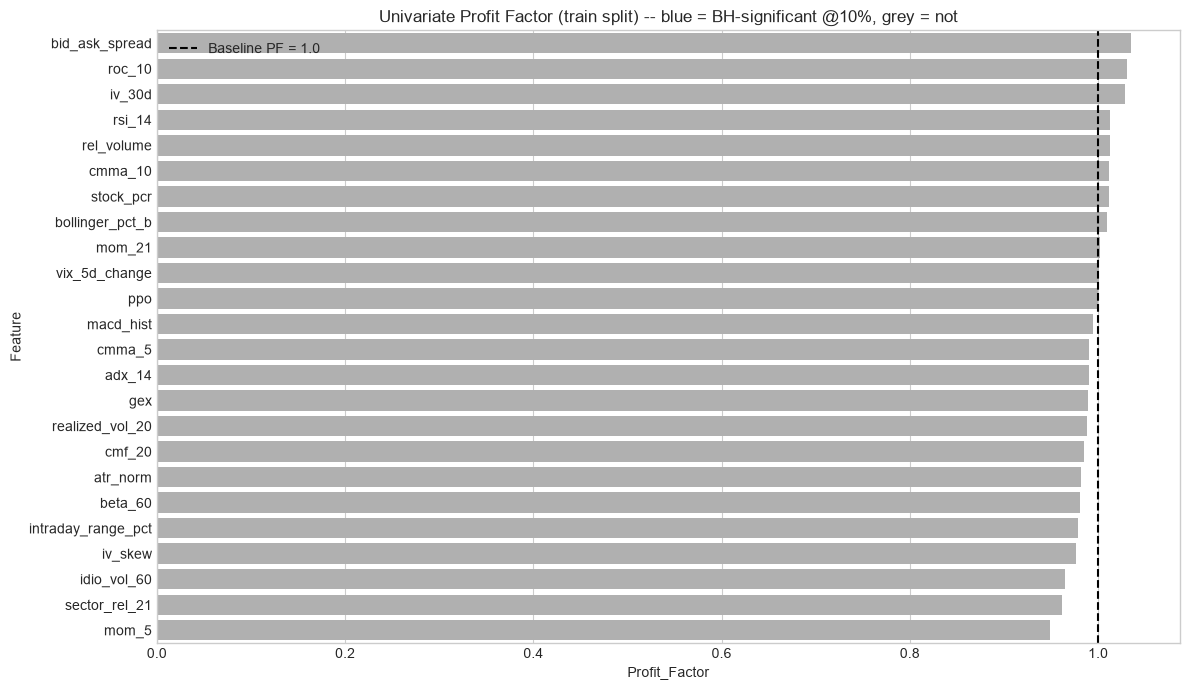

In [22]:
print("Full feature ranking (Profit Factor + Alpha + MI), computed on the training split only:")
print(rank.to_string(index=False))

plt.figure(figsize=(12, 7))
bar_colors = ["#4C72B0" if sig else "#B0B0B0" for sig in rank["BH_significant_10pct"]]
sns.barplot(data=rank, x="Profit_Factor", y="Feature", palette=bar_colors, dodge=False)
plt.axvline(1.0, color="black", linestyle="--", label="Baseline PF = 1.0")
plt.title("Univariate Profit Factor (train split) -- blue = BH-significant @10%, grey = not")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# # --- Actually perform the drop-4 step ------------------------------------
# # The original notebook only displayed this ranking; it never removed
# # anything, despite the write-up describing a "drop-4" filter. Implement it
# # here: drop the 4 lowest-Profit-Factor individual features (train-split PF),
# # keep the calendar block as one protected unit.
# N_DROP = 4
# dropped_features = rank.sort_values("Profit_Factor").head(N_DROP)["Feature"].tolist()
# kept_candidate_cols = [f for f in candidate_cols if f not in dropped_features]
# selected_feature_cols = kept_candidate_cols + calendar_cols  # calendar always protected

# print(f"\nDropped (lowest Profit Factor, train split): {dropped_features}")
# print(f"Selected feature set ({len(selected_feature_cols)} columns: "
#       f"{len(kept_candidate_cols)} candidates + {len(calendar_cols)} calendar):")
# print(selected_feature_cols)

# n_sig = int(rank["BH_significant_10pct"].sum())
# print(f"\nOf the {len(candidate_cols)} candidates tested, {n_sig} are statistically significant "
#       f"at the 10% BH-adjusted level -- treat the rest of the ranking as exploratory, not a confirmed edge.")